# Part B: Sentiment Classification for Women's Clothing Reviews

This notebook answers Part B Questions 1 to 4 using the Women's Clothing E-Commerce Reviews dataset. The classification task is to predict a three-class sentiment label from customer review text.

Sentiment labels are derived from the original `Rating` column:

| Rating | Sentiment label |
|---:|:---|
| 1-2 | Negative |
| 3 | Neutral |
| 4-5 | Positive |

This mapping keeps the task supervised, transparent, and directly connected to the dataset's existing annotation.

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings('ignore', category=FutureWarning)

DATA_PATH = Path('../data/Womens Clothing E-Commerce Reviews.csv')
RANDOM_STATE = 42
SENTIMENT_ORDER = ['negative', 'neutral', 'positive']

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 140)
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

## Q1. Dataset Selection and Exploratory Data Analysis

The dataset is suitable for supervised text classification because each review contains natural-language text and a numerical customer rating. The review text provides the predictor variable, while the rating provides a clear basis for deriving sentiment labels. This makes the dataset appropriate for comparing multiple predictive models for sentiment analysis.

In [2]:
def make_sentiment_label(rating: int) -> str:
    if rating <= 2:
        return 'negative'
    if rating == 3:
        return 'neutral'
    return 'positive'


def clean_text(text: str) -> str:
    text = re.sub(r'\s+', ' ', str(text)).strip()
    return text


def prepare_reviews(path: Path) -> pd.DataFrame:
    raw = pd.read_csv(path)
    raw = raw.rename(columns={raw.columns[0]: 'Original Row'})

    prepared = raw.copy()
    prepared['Title'] = prepared['Title'].fillna('')
    prepared['Review Text'] = prepared['Review Text'].fillna('')
    prepared['text'] = (prepared['Title'] + ' ' + prepared['Review Text']).map(clean_text)
    prepared = prepared[prepared['text'].str.len() > 0].copy()
    prepared['sentiment'] = prepared['Rating'].map(make_sentiment_label)
    prepared['word_count'] = prepared['text'].str.split().str.len()
    prepared['character_count'] = prepared['text'].str.len()
    return raw, prepared


raw_reviews, reviews = prepare_reviews(DATA_PATH)

overview = pd.DataFrame({
    'Metric': [
        'Original rows',
        'Rows with usable text',
        'Columns',
        'Classification target',
        'Input text field',
    ],
    'Value': [
        f'{len(raw_reviews):,}',
        f'{len(reviews):,}',
        f'{raw_reviews.shape[1]:,}',
        'Sentiment derived from Rating',
        'Title + Review Text',
    ],
})
overview

,Metric,Value
0,Original rows,"23,486"
1,Rows with usable text,"22,642"
2,Columns,11
3,Classification target,Sentiment derived from Rating
4,Input text field,Title + Review Text


In [3]:
missing_summary = (
    raw_reviews.isna()
    .sum()
    .rename('Missing Values')
    .to_frame()
    .assign(**{'Missing %': lambda table: (table['Missing Values'] / len(raw_reviews) * 100).round(2)})
    .query('`Missing Values` > 0')
    .sort_values('Missing Values', ascending=False)
)
missing_summary

,Missing Values,Missing %
Title,3810,16.22
Review Text,845,3.60
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06


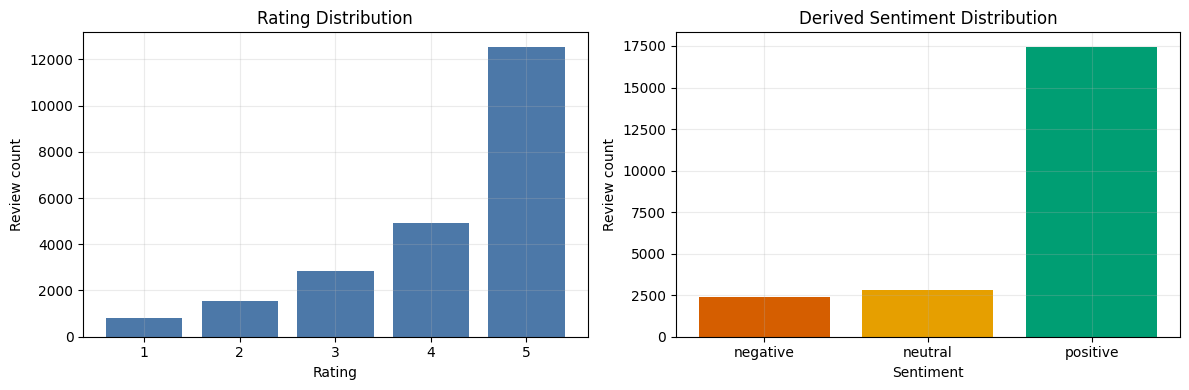

,Sentiment,Reviews,Share %
0,negative,2370,10.47
1,neutral,2823,12.47
2,positive,17449,77.06


In [4]:
rating_summary = (
    reviews['Rating']
    .value_counts()
    .sort_index()
    .rename_axis('Rating')
    .reset_index(name='Reviews')
)

sentiment_summary = (
    reviews['sentiment']
    .value_counts()
    .reindex(SENTIMENT_ORDER)
    .rename_axis('Sentiment')
    .reset_index(name='Reviews')
)
sentiment_summary['Share %'] = (sentiment_summary['Reviews'] / len(reviews) * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(rating_summary['Rating'].astype(str), rating_summary['Reviews'], color='#4C78A8')
axes[0].set_title('Rating Distribution')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Review count')

axes[1].bar(sentiment_summary['Sentiment'], sentiment_summary['Reviews'], color=['#D55E00', '#E69F00', '#009E73'])
axes[1].set_title('Derived Sentiment Distribution')
axes[1].set_xlabel('Sentiment')
axes[1].set_ylabel('Review count')
plt.tight_layout()
plt.show()

sentiment_summary

In [5]:
length_summary = (
    reviews.groupby('sentiment')[['word_count', 'character_count']]
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
    .reindex(SENTIMENT_ORDER)
)
length_summary

word_count                        character_count                        
               count   mean median min  max           count    mean median min  max
sentiment                                                                          
negative        2370  63.98   63.0   6  118            2370  331.39  327.0  36  557
neutral         2823  67.61   68.0   3  117            2823  346.14  346.0  21  554
positive       17449  62.25   61.0   2  121           17449  321.71  313.0  11  552

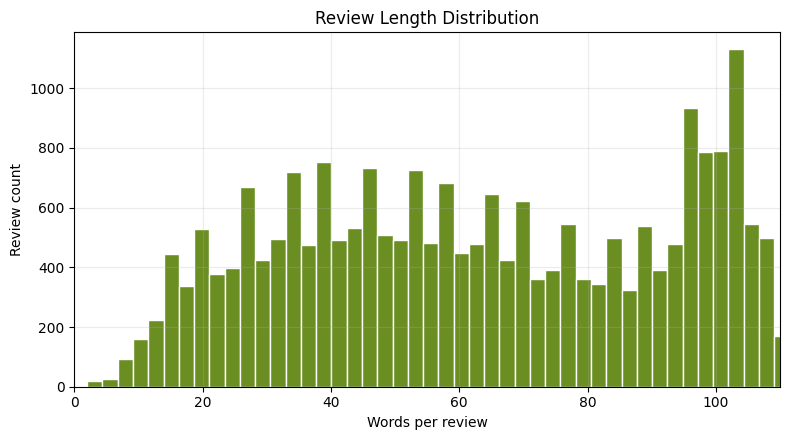

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(reviews['word_count'], bins=50, color='#6B8E23', edgecolor='white')
ax.set_title('Review Length Distribution')
ax.set_xlabel('Words per review')
ax.set_ylabel('Review count')
ax.set_xlim(0, reviews['word_count'].quantile(0.99))
plt.tight_layout()
plt.show()

In [7]:
category_summary = (
    reviews.groupby(['Department Name', 'sentiment'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SENTIMENT_ORDER)
)
category_summary['total'] = category_summary.sum(axis=1)
category_summary = category_summary.sort_values('total', ascending=False)
category_summary.head(10)

sentiment,negative,neutral,positive,total
Department Name,,,,
Tops,1096,1300,7652,10048
Dresses,681,830,4635,6146
Bottoms,317,407,2938,3662
Intimate,147,177,1329,1653
Jackets,108,90,804,1002
Trend,21,19,78,118


In [8]:
vectorizer_for_eda = CountVectorizer(stop_words='english', min_df=5)
unigram_matrix = vectorizer_for_eda.fit_transform(reviews['text'])
unigram_counts = pd.Series(
    unigram_matrix.sum(axis=0).A1,
    index=vectorizer_for_eda.get_feature_names_out(),
).sort_values(ascending=False)

bigram_vectorizer_for_eda = CountVectorizer(stop_words='english', ngram_range=(2, 2), min_df=5)
bigram_matrix = bigram_vectorizer_for_eda.fit_transform(reviews['text'])
bigram_counts = pd.Series(
    bigram_matrix.sum(axis=0).A1,
    index=bigram_vectorizer_for_eda.get_feature_names_out(),
).sort_values(ascending=False)

vocabulary_summary = pd.DataFrame({
    'Measure': ['Usable reviews', 'Unique unigram terms', 'Unique bigram terms'],
    'Value': [f'{len(reviews):,}', f'{len(unigram_counts):,}', f'{len(bigram_counts):,}'],
})

pd.concat(
    [
        vocabulary_summary,
        pd.DataFrame({'Measure': ['Most frequent unigram', 'Most frequent bigram'], 'Value': [unigram_counts.index[0], bigram_counts.index[0]]}),
    ],
    ignore_index=True,
)

,Measure,Value
0,Usable reviews,"22,642"
1,Unique unigram terms,"4,774"
2,Unique bigram terms,"18,079"
3,Most frequent unigram,dress
4,Most frequent bigram,true size


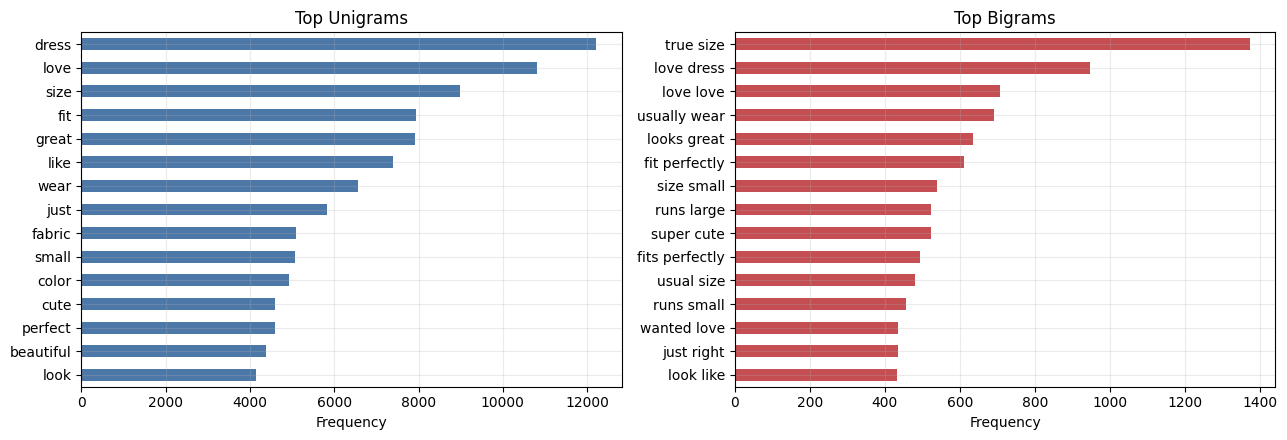

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
unigram_counts.head(15).sort_values().plot(kind='barh', ax=axes[0], color='#4C78A8')
axes[0].set_title('Top Unigrams')
axes[0].set_xlabel('Frequency')

bigram_counts.head(15).sort_values().plot(kind='barh', ax=axes[1], color='#C44E52')
axes[1].set_title('Top Bigrams')
axes[1].set_xlabel('Frequency')
plt.tight_layout()
plt.show()

The exploratory analysis shows that positive reviews dominate the dataset, while neutral and negative reviews are smaller classes. Because of this imbalance, accuracy alone is not enough for model comparison. Macro F1 is used as the main metric because it gives each sentiment class equal importance.

## Q2. Supervised Text Classification Models

Four supervised models are trained with the same TF-IDF text representation so the comparison focuses on model behaviour rather than different feature pipelines.

In [10]:
X = reviews['text']
y = reviews['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    'Split': ['Training set', 'Test set'],
    'Rows': [len(X_train), len(X_test)],
    'Share %': [round(len(X_train) / len(X) * 100, 2), round(len(X_test) / len(X) * 100, 2)],
})
split_summary

,Split,Rows,Share %
0,Training set,18113,80.0
1,Test set,4529,20.0


In [11]:
def make_text_pipeline(classifier) -> Pipeline:
    return Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', min_df=2, max_features=5000, ngram_range=(1, 2))),
        ('model', classifier),
    ])


baseline_models = {
    'Multinomial Naive Bayes': make_text_pipeline(MultinomialNB()),
    'Logistic Regression': make_text_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    'Linear SVM': make_text_pipeline(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
    'Random Forest': make_text_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced_subsample')),
}


def evaluate_predictions(model_name: str, true_labels, predicted_labels) -> dict[str, float | str]:
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(true_labels, predicted_labels),
        'Macro F1': f1_score(true_labels, predicted_labels, average='macro'),
        'Weighted F1': f1_score(true_labels, predicted_labels, average='weighted'),
    }


baseline_rows = []
baseline_predictions = {}

for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    baseline_predictions[name] = predictions
    baseline_rows.append(evaluate_predictions(name, y_test, predictions))

baseline_results = pd.DataFrame(baseline_rows).sort_values('Macro F1', ascending=False)
baseline_results[['Accuracy', 'Macro F1', 'Weighted F1']] = baseline_results[['Accuracy', 'Macro F1', 'Weighted F1']].round(4)
baseline_results

,Model,Accuracy,Macro F1,Weighted F1
1,Logistic Regression,0.7920,0.6289,0.8099
2,Linear SVM,0.8130,0.6241,0.8162
0,Multinomial Naive Bayes,0.8088,0.5019,0.7612
3,Random Forest,0.8057,0.4808,0.7496


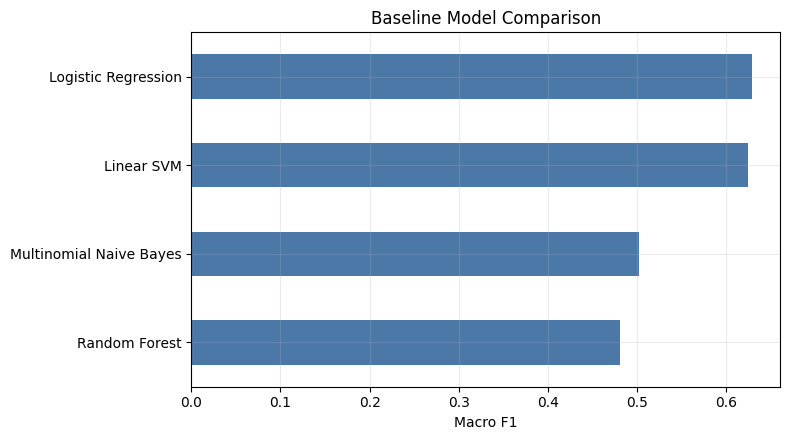

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
baseline_results.sort_values('Macro F1').plot(
    x='Model',
    y='Macro F1',
    kind='barh',
    legend=False,
    ax=ax,
    color='#4C78A8',
)
ax.set_title('Baseline Model Comparison')
ax.set_xlabel('Macro F1')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## Q3. Hyperparameter Selection

Grid search is used to tune each model with macro F1 scoring. The grids are intentionally compact so the notebook remains readable and reproducible while still testing meaningful model settings.

In [13]:
hyperparameter_notes = pd.DataFrame([
    {'Model': 'Multinomial Naive Bayes', 'Hyperparameter': 'model__alpha', 'Purpose': 'Controls smoothing so unseen or rare terms do not receive zero probability.'},
    {'Model': 'Logistic Regression', 'Hyperparameter': 'model__C', 'Purpose': 'Controls regularization strength; smaller values apply stronger regularization.'},
    {'Model': 'Linear SVM', 'Hyperparameter': 'model__C', 'Purpose': 'Controls the trade-off between margin width and classification errors.'},
    {'Model': 'Random Forest', 'Hyperparameter': 'model__max_depth', 'Purpose': 'Limits tree depth to reduce overfitting.'},
    {'Model': 'Random Forest', 'Hyperparameter': 'model__min_samples_split', 'Purpose': 'Sets the minimum samples required to split a tree node.'},
])
hyperparameter_notes

,Model,Hyperparameter,Purpose
0,Multinomial Naive Bayes,model__alpha,Controls smoothing so unseen or rare terms do not receive zero probability.
1,Logistic Regression,model__C,Controls regularization strength; smaller values apply stronger regularization.
2,Linear SVM,model__C,Controls the trade-off between margin width and classification errors.
3,Random Forest,model__max_depth,Limits tree depth to reduce overfitting.
4,Random Forest,model__min_samples_split,Sets the minimum samples required to split a tree node.


In [14]:
search_spaces = {
    'Multinomial Naive Bayes': {
        'pipeline': make_text_pipeline(MultinomialNB()),
        'parameters': {'model__alpha': [0.1, 0.5, 1.0]},
    },
    'Logistic Regression': {
        'pipeline': make_text_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
        'parameters': {'model__C': [0.5, 1.0, 2.0]},
    },
    'Linear SVM': {
        'pipeline': make_text_pipeline(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
        'parameters': {'model__C': [0.5, 1.0, 2.0]},
    },
    'Random Forest': {
        'pipeline': make_text_pipeline(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced_subsample')),
        'parameters': {'model__max_depth': [30, None], 'model__min_samples_split': [2, 5]},
    },
}

search_rows = []
best_models = {}

def format_parameters(parameters: dict) -> str:
    return ', '.join(f'{key}={value}' for key, value in parameters.items())

for name, config in search_spaces.items():
    search = GridSearchCV(
        estimator=config['pipeline'],
        param_grid=config['parameters'],
        scoring='f1_macro',
        cv=3,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    search_rows.append({
        'Model': name,
        'Best Parameters': format_parameters(search.best_params_),
        'Best CV Macro F1': search.best_score_,
    })

search_results = pd.DataFrame(search_rows).sort_values('Best CV Macro F1', ascending=False)
search_results['Best CV Macro F1'] = search_results['Best CV Macro F1'].round(4)
search_results

,Model,Best Parameters,Best CV Macro F1
1,Logistic Regression,model__C=0.5,0.6236
2,Linear SVM,model__C=0.5,0.6168
3,Random Forest,"model__max_depth=30, model__min_samples_split=5",0.5763
0,Multinomial Naive Bayes,model__alpha=0.1,0.5422


## Q4. Evaluation and Discussion

The tuned models are evaluated on the held-out test set. Accuracy is reported for general correctness, while macro F1 and weighted F1 provide a clearer view of performance under class imbalance.

In [15]:
tuned_rows = []
tuned_predictions = {}

for name, model in best_models.items():
    predictions = model.predict(X_test)
    tuned_predictions[name] = predictions
    tuned_rows.append(evaluate_predictions(name, y_test, predictions))

tuned_results = pd.DataFrame(tuned_rows).sort_values('Macro F1', ascending=False)
tuned_results[['Accuracy', 'Macro F1', 'Weighted F1']] = tuned_results[['Accuracy', 'Macro F1', 'Weighted F1']].round(4)
tuned_results

,Model,Accuracy,Macro F1,Weighted F1
1,Logistic Regression,0.7933,0.6330,0.8113
2,Linear SVM,0.8183,0.6294,0.8204
3,Random Forest,0.8002,0.5873,0.7963
0,Multinomial Naive Bayes,0.8209,0.5619,0.7903


In [16]:
best_model_name = tuned_results.iloc[0]['Model']
best_predictions = tuned_predictions[best_model_name]

print(f'Best model by macro F1: {best_model_name}')
print()
print(classification_report(y_test, best_predictions, labels=SENTIMENT_ORDER, digits=4))

Best model by macro F1: Logistic Regression

              precision    recall  f1-score   support

    negative     0.5309    0.6350    0.5783       474
     neutral     0.3469    0.5115    0.4134       565
    positive     0.9597    0.8605    0.9074      3490

    accuracy                         0.7933      4529
   macro avg     0.6125    0.6690    0.6330      4529
weighted avg     0.8384    0.7933    0.8113      4529



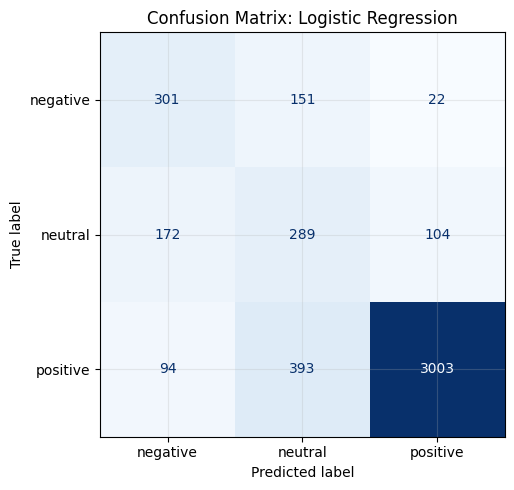

In [17]:
cm = confusion_matrix(y_test, best_predictions, labels=SENTIMENT_ORDER)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SENTIMENT_ORDER)
fig, ax = plt.subplots(figsize=(6, 5))
display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Confusion Matrix: {best_model_name}')
plt.tight_layout()
plt.show()

In [18]:
comparison = baseline_results.merge(
    tuned_results,
    on='Model',
    suffixes=(' Baseline', ' Tuned'),
)
comparison = comparison[[
    'Model',
    'Macro F1 Baseline',
    'Macro F1 Tuned',
    'Accuracy Baseline',
    'Accuracy Tuned',
    'Weighted F1 Baseline',
    'Weighted F1 Tuned',
]]
comparison

,Model,Macro F1 Baseline,Macro F1 Tuned,Accuracy Baseline,Accuracy Tuned,Weighted F1 Baseline,Weighted F1 Tuned
0,Logistic Regression,0.6289,0.6330,0.7920,0.7933,0.8099,0.8113
1,Linear SVM,0.6241,0.6294,0.8130,0.8183,0.8162,0.8204
2,Multinomial Naive Bayes,0.5019,0.5619,0.8088,0.8209,0.7612,0.7903
3,Random Forest,0.4808,0.5873,0.8057,0.8002,0.7496,0.7963


### Discussion

The best model is selected using macro F1 because the dataset is not evenly distributed across negative, neutral, and positive sentiment. A model with high accuracy may still perform poorly on minority classes if it mainly predicts the dominant positive class. Macro F1 reduces this problem by giving equal weight to each class.

Linear models are expected to perform strongly on this task because TF-IDF creates a high-dimensional sparse representation of review terms. Naive Bayes is useful as a simple probabilistic baseline, while Random Forest provides a non-linear comparison model. The final choice should prioritize the tuned model with the highest macro F1, then use the classification report and confusion matrix to confirm whether performance is acceptable across all three sentiment classes.